# Exploratory Data Analysis (EDA) on Hotel Booking Demand Dataset
#### Submitted by: Madhumathi
#### Course: B.Sc Data Science
#### College: SDNB Vaishnav College for Women, Chrmpet
#### Date : 04.11.2026

---

#### Importing the Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading the Dataset

In [5]:
df = pd.read_csv(r"C:\Users\MADHUMATHI\Desktop\Weekly_task\Hotel_Booking.zip")
print("Dataset loaded successfully")

Dataset loaded successfully


#### First five rows

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


#### Last five rows

In [7]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


#### Checking the dataset dimensions

In [8]:
df.shape

(119390, 32)

#### Checking column names

In [9]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

#### Checking the Dataset Data Types

In [10]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

#### Checking missing values

In [11]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

#### Checking missing values count in percentage

In [12]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

company                           94.306893
agent                             13.686238
country                            0.408744
children                           0.003350
arrival_date_month                 0.000000
arrival_date_week_number           0.000000
hotel                              0.000000
is_canceled                        0.000000
stays_in_weekend_nights            0.000000
arrival_date_day_of_month          0.000000
adults                             0.000000
stays_in_week_nights               0.000000
babies                             0.000000
meal                               0.000000
lead_time                          0.000000
arrival_date_year                  0.000000
distribution_channel               0.000000
market_segment                     0.000000
previous_bookings_not_canceled     0.000000
is_repeated_guest                  0.000000
reserved_room_type                 0.000000
assigned_room_type                 0.000000
booking_changes                 

#### Handling missing values

##### 1. Country - missing due to not defined, fill with 'Unknown'

In [13]:
df['country'] = df['country'].fillna('Unknown')

##### 2. Children - has NaN, fill with 0

In [14]:
df['children'] = df['children'].fillna(0)

##### 3. Agent - 0 means no agent, fill NaN with 0

In [15]:
df['agent'] = df['agent'].fillna(0)

##### 4. Company - 0 means no company

In [16]:
df['company'] = df['company'].fillna(0)

In [17]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

#### Checking for duplicate records

In [18]:
df.duplicated().sum()

np.int64(31994)

#### Statistical summary of numerical columns

In [19]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103886,0.007949,0.031912,0.087118,0.137097,0.221124,74.828319,10.775157,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398555,0.097436,0.175767,0.844336,1.497437,0.652306,107.141953,53.943884,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,0.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,152.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


#### Feature Engineering and Further Analysis

##### 1. Total Stay Duration

In [20]:
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

##### 2. Total Guests

In [21]:
df['total_guests'] = df['adults'] + df['children'] + df['babies']

##### 3. Total Nights vs ADR

In [22]:
df[['stays_in_weekend_nights','stays_in_week_nights','total_stay','adults','children','babies','total_guests']].head()

,stays_in_weekend_nights,stays_in_week_nights,total_stay,adults,children,babies,total_guests
0,0,0,0,2,0.0,0,2.0
1,0,0,0,2,0.0,0,2.0
2,0,1,1,1,0.0,0,1.0
3,0,1,1,1,0.0,0,1.0
4,0,2,2,2,0.0,0,2.0


#### Cancellation percentage

In [23]:
cancellation_rate = df['is_canceled'].mean() * 100
print(f"Overall Cancellation Rate: {cancellation_rate:.2f}%")

Overall Cancellation Rate: 37.04%


#### Cancellation by Hotel Type

In [24]:
df.groupby('hotel')['is_canceled'].mean() * 100

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64

#### Distribution of Lead Time

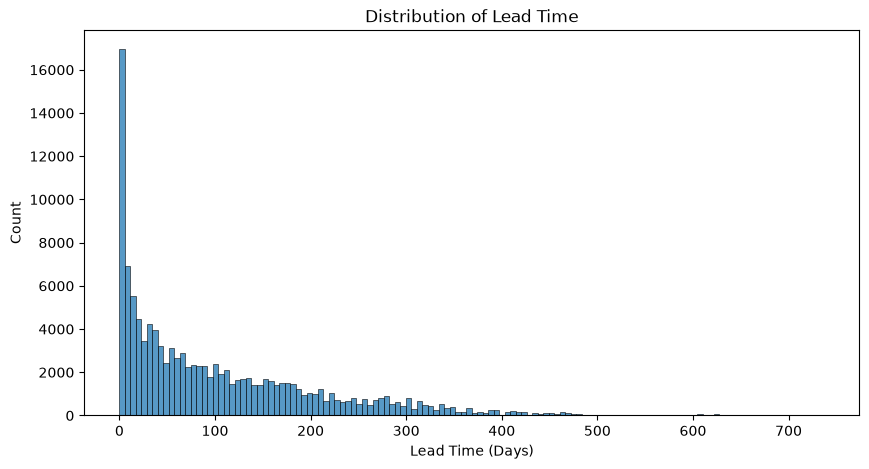

In [28]:
plt.figure(figsize=(10,5))
sns.histplot(df['lead_time'])
plt.title('Distribution of Lead Time')
plt.xlabel('Lead Time (Days)')
plt.show()

#### Outliers in Lead Time and ADR

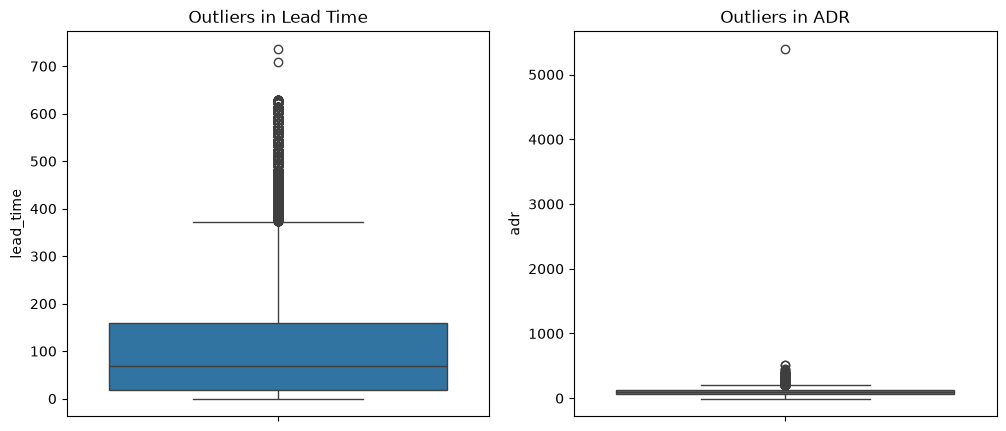

In [27]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(y=df['lead_time'])
plt.title('Outliers in Lead Time')

plt.subplot(1,2,2)
sns.boxplot(y=df['adr'])
plt.title('Outliers in ADR')

plt.show()

#### Resort vs City Hotel Trends

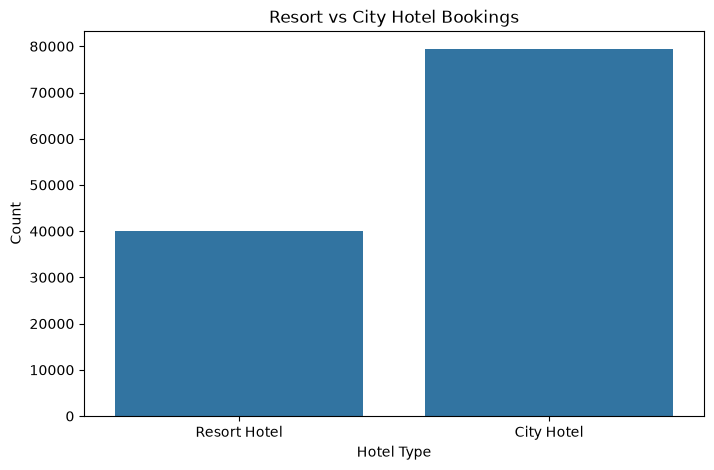

In [29]:
plt.figure(figsize=(8,5))
sns.countplot(x='hotel', data=df)
plt.title('Resort vs City Hotel Bookings')
plt.xlabel('Hotel Type')
plt.ylabel('Count')
plt.show()

#### Cancellation Rate by Hotel Type

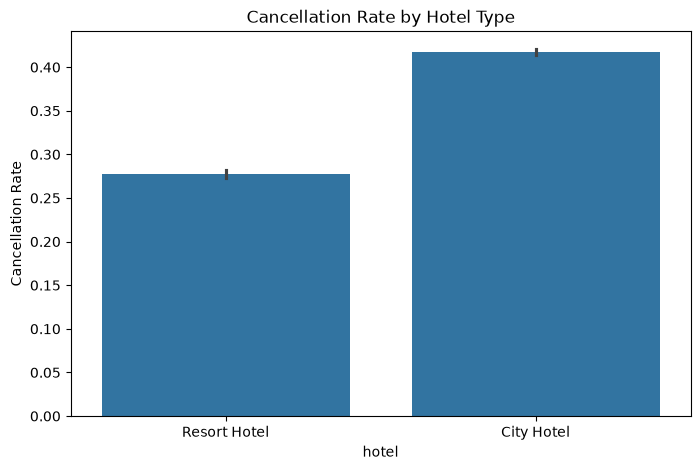

In [30]:
plt.figure(figsize=(8,5))
sns.barplot(x='hotel', y='is_canceled', data=df)
plt.title('Cancellation Rate by Hotel Type')
plt.ylabel('Cancellation Rate')
plt.show()

#### Market Segment vs Cancellation

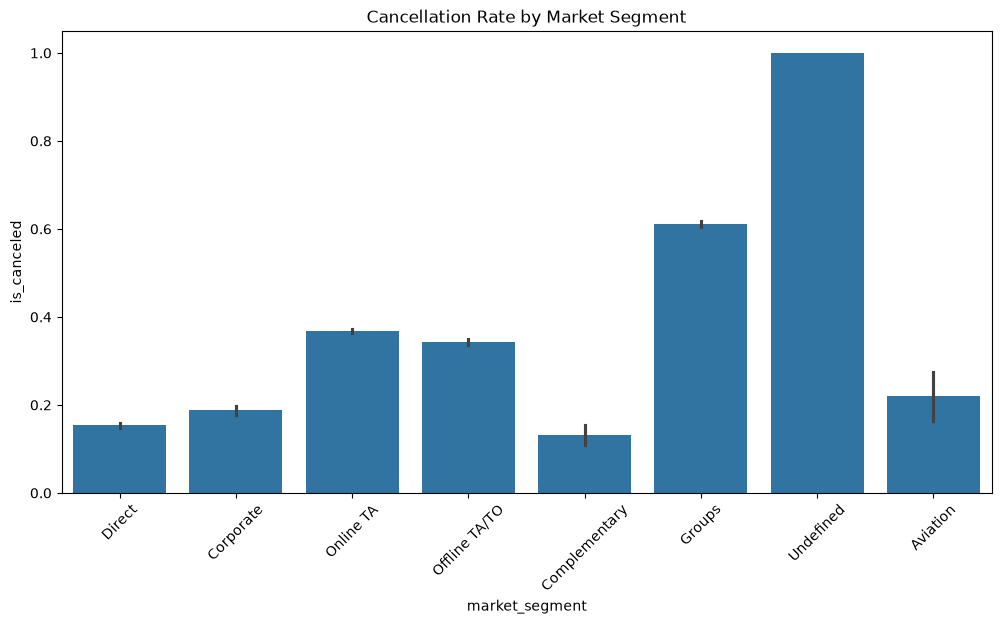

In [31]:
plt.figure(figsize=(12,6))
sns.barplot(x='market_segment', y='is_canceled', data=df)
plt.title('Cancellation Rate by Market Segment')
plt.xticks(rotation=45)
plt.show()

#### Lead Time vs Cancellation

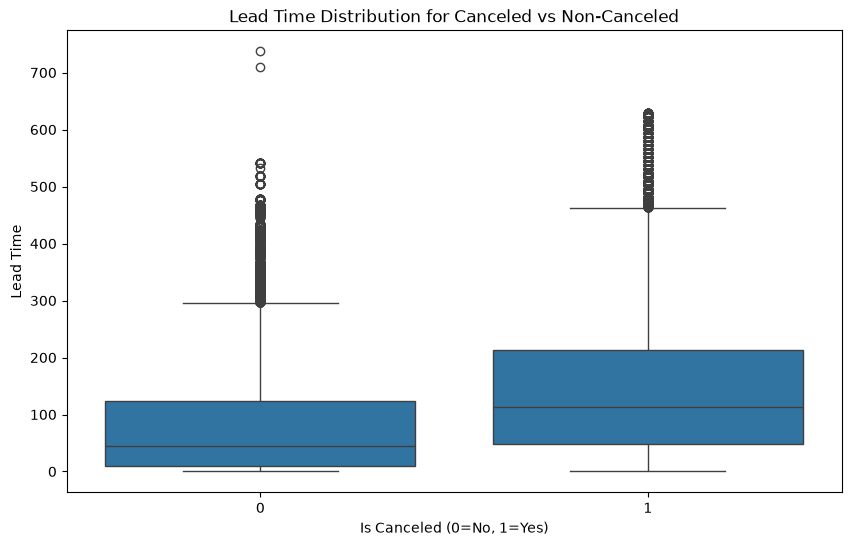

In [32]:
plt.figure(figsize=(10,6))
sns.boxplot(x='is_canceled', y='lead_time', data=df)
plt.title('Lead Time Distribution for Canceled vs Non-Canceled')
plt.xlabel('Is Canceled (0=No, 1=Yes)')
plt.ylabel('Lead Time')
plt.show()

#### Lead Time vs Cancellation

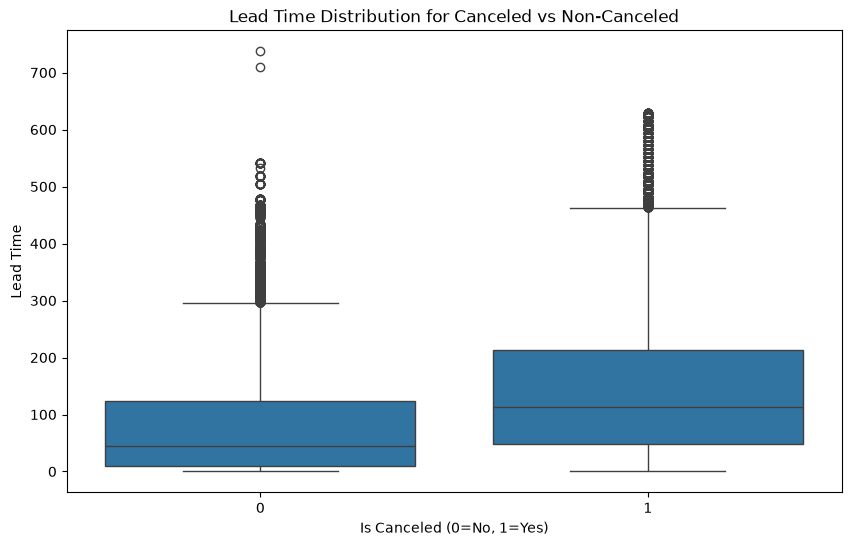

In [33]:
plt.figure(figsize=(10,6))
sns.boxplot(x='is_canceled', y='lead_time', data=df)
plt.title('Lead Time Distribution for Canceled vs Non-Canceled')
plt.xlabel('Is Canceled (0=No, 1=Yes)')
plt.ylabel('Lead Time')
plt.show()

#### Monthly Arrival Trends

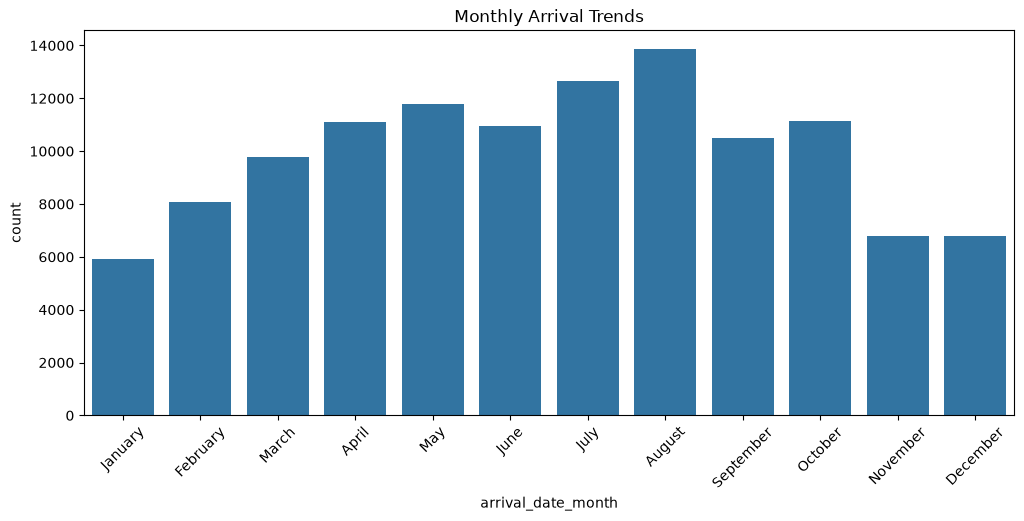

In [34]:
# Order months correctly
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

plt.figure(figsize=(12,5))
sns.countplot(x='arrival_date_month', data=df, order=month_order)
plt.title('Monthly Arrival Trends')
plt.xticks(rotation=45)
plt.show()

#### ADR Fluctuations by Month - Pricing Strategy

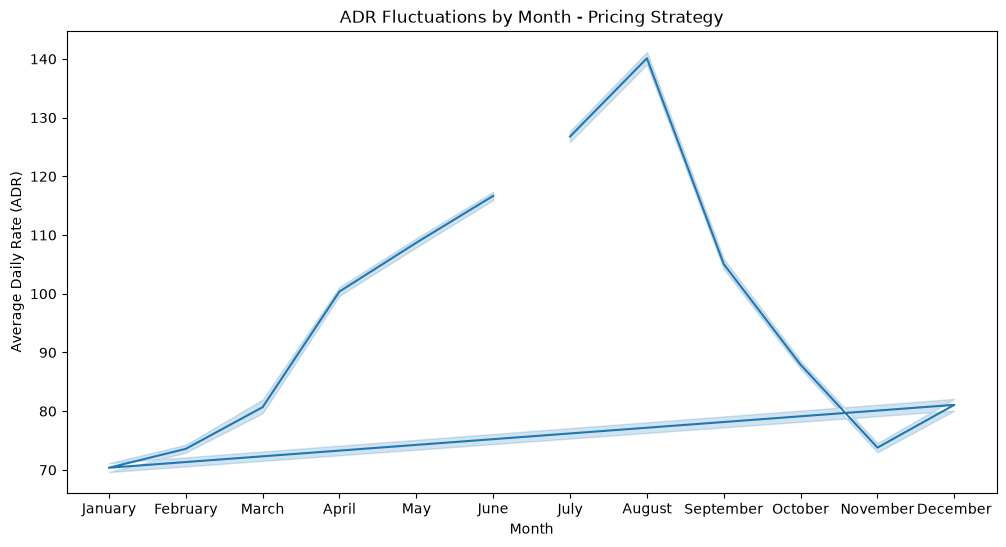

In [35]:
plt.figure(figsize=(12,6))
sns.lineplot(x='arrival_date_month', y='adr', data=df, estimator='mean', sort=False)
plt.title('ADR Fluctuations by Month - Pricing Strategy')
plt.xlabel('Month')
plt.ylabel('Average Daily Rate (ADR)')
plt.show()

#### Checking the Relationship Between Numerical Columns

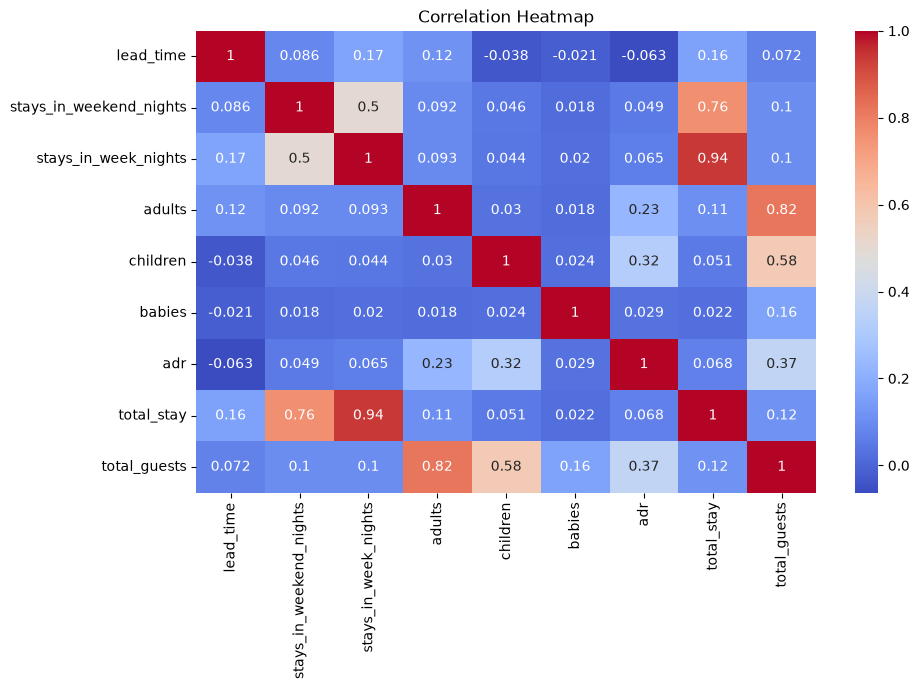

In [36]:
plt.figure(figsize=(10,6))
corr = df[['lead_time','stays_in_weekend_nights','stays_in_week_nights','adults','children','babies','adr','total_stay','total_guests']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Final Dataset Information

In [37]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 34 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   hotel                           119390 non-null  str     
 1   is_canceled                     119390 non-null  int64   
 2   lead_time                       119390 non-null  int64   
 3   arrival_date_year               119390 non-null  int64   
 4   arrival_date_month              119390 non-null  category
 5   arrival_date_week_number        119390 non-null  int64   
 6   arrival_date_day_of_month       119390 non-null  int64   
 7   stays_in_weekend_nights         119390 non-null  int64   
 8   stays_in_week_nights            119390 non-null  int64   
 9   adults                          119390 non-null  int64   
 10  children                        119390 non-null  float64 
 11  babies                          119390 non-null  int64   
 12  meal         

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_stay,total_guests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,2,2.0


---

# REPORT: Hotel Booking Demand Analysis

---

### 1. Introduction
The dataset was loaded using Pandas. First and last five rows were examined, dimensions, column names and data types were checked. Missing values in country, agent, company, children were identified and handled appropriately.

### 2. Objectives - Week 13 & 14
- To inspect reservation status, cancellation flags, and lead time distributions.
- To handle missing data across agent, company, country codes.
- To engineer stay duration features (Total Stay = Weekend + Weekday Nights) and total guests.
- To compare demand and cancellation patterns between Resort and City hotels.
- To analyze relationship between lead time and cancellation for revenue management.

### 3. Data Visualization and Analysis

**Distribution of Lead Time:** Most bookings have low lead time (0-100 days), but some have very high lead time up to 700 days. High lead time bookings have higher cancellation risk.

**Resort vs City Hotel Trends:** City Hotel has significantly more bookings than Resort Hotel (~61% vs 39%). City hotels face higher business demand.

**Cancellation Rate by Hotel Type:** City Hotel has higher cancellation rate (~42%) compared to Resort Hotel (~28%). Overall cancellation rate is ~37%.

**Market Segment vs Cancellation:** Online TA has highest bookings and high cancellation. Aviation and Corporate have lower cancellations. This shows need for different overbooking policies per segment.

**Lead Time vs Cancellation:** Canceled bookings have much higher median lead time (around 120 days) vs non-canceled (around 50 days). Longer lead time = higher risk.

**Monthly Arrival Trends:** July and August are peak seasons with highest arrivals. November and December are low seasons.

**ADR Pricing Strategy:** ADR is highest in July-August (peak season) and lowest in November. Pricing fluctuates with seasonality - dynamic pricing opportunity.

**Correlation:** Lead_time positively correlates with cancellation. ADR correlates with total stay and guests.

### 4. Feature Engineering
- total_stay = stays_in_weekend_nights + stays_in_week_nights
- total_guests = adults + children + babies
- country filled with Unknown, agent/company with 0

### 5. Results and Observations
- Total records: 119390
- Total columns: 34 after engineering
- Missing values after cleaning: 0
- Overall cancellation rate: ~37%
- City Hotel cancellation: ~42% , Resort Hotel: ~28%
- Peak months: July, August
- ADR average: ~102
- Lead time average: ~104 days
- High lead time is main driver of cancellation

### 6. Conclusion
This project demonstrates EDA on hotel booking demand data. Lead time is the strongest predictor of cancellation. City hotels need stricter cancellation policies and overbooking protection. Seasonal trends show clear peak in summer months, allowing for higher ADR pricing. Market segment analysis suggests targeted promotions for low-cancellation segments like Corporate. Recommendations include reducing lead time offers, implementing non-refundable discounts for high lead time bookings, and dynamic pricing based on seasonality to optimize revenue management.